# 06 · Validação robusta sem vazamento / Leakage-safe validation

Protocolo, com as decisões tomadas **antes** de olhar o teste final:

```
dados limpos (1.116 linhas, 848 perfis)
 └─ divisão agrupada por perfil e estratificada pelo evento
     ├─ 80% DESENVOLVIMENTO → CV ingênua vs agrupada · controle negativo (desfecho embaralhado)
     │                       → CV repetida e aninhada · regra de seleção · calibração
     └─ 20% TESTE FINAL     → intocado até a seção 6; avaliado UMA vez, só reportado
```

Salvaguardas contra *data leakage*:

| Risco | Salvaguarda |
|---|---|
| Mesma pessoa no treino e no teste | Divisões agrupadas por `profile_id` |
| Pré-processamento vendo o teste | `DesignMatrixBuilder` ajustado só no treino de cada fold (categorias raras, referência) |
| Hiperparâmetros vendo o teste | Ajuste aninhado dentro de cada fold de treino |
| Escolha do modelo vendo o teste | Regra de seleção pré-definida, aplicada só à CV do desenvolvimento |
| Vazamento por caminho não previsto | Controle negativo: com o desfecho embaralhado, o C-index precisa ficar em ≈ 0,5 |

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))  # works even without `pip install -e .`
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from turnover_survival import config, data, nonparametric, models, evaluation

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:.3f}".format)
config.FIGURES_DIR.mkdir(parents=True, exist_ok=True)
T, E = config.DURATION_COL, config.EVENT_COL

df = data.load_clean()
print(f"{len(df)} employees | {df[E].sum()} left | {1 - df[E].mean():.1%} censored")

1116 employees | 560 left | 49.8% censored


In [2]:
dev, holdout = data.split(df, test_size=0.2, random_state=config.RANDOM_STATE)
print(f"development: {len(dev)} rows / {dev[config.GROUP_COL].nunique()} profiles | "
      f"final test: {len(holdout)} rows / {holdout[config.GROUP_COL].nunique()} profiles")
print("profiles in both:", len(set(dev[config.GROUP_COL]) & set(holdout[config.GROUP_COL])))
print(f"event rate: dev {dev[E].mean():.3f} | final test {holdout[E].mean():.3f}")

development: 874 rows / 670 profiles | final test: 242 rows / 178 profiles
profiles in both: 0
event rate: dev 0.510 | final test 0.471


> A partir daqui, até a seção 6, **só `dev` é usado**.

## 1 · Vazamento por pessoa repetida: CV ingênua vs agrupada
Hiperparâmetros fixos, para isolar o efeito da divisão.

In [3]:
fixed = {
    "Cox PH": lambda d: models.fit_cox(d, penalizer=0.01, robust=False),
    "Random Survival Forest": lambda d: models.fit_rsf(d, n_estimators=200),
}
leak = pd.concat([
    evaluation.cross_validate(dev, fixed, n_splits=5, n_repeats=3, grouped=g, verbose=False)[0]
    .assign(split="grouped" if g else "naive")
    for g in (False, True)
])
leak_tab = leak.pivot_table(index="model", columns="split", values=["c_index", "integrated_brier"], aggfunc="mean")
for m in ["c_index", "integrated_brier"]:
    leak_tab[(m, "naive − grouped")] = leak_tab[(m, "naive")] - leak_tab[(m, "grouped")]
leak_tab

c_index       integrated_brier               c_index  \
split                  grouped naive          grouped naive naive − grouped   
model                                                                         
Cox PH                   0.613 0.619            0.198 0.198           0.006   
Random Survival Forest   0.621 0.630            0.195 0.194           0.009   

                       integrated_brier  
split                   naive − grouped  
model                                    
Cox PH                           -0.000  
Random Survival Forest           -0.001

Se a CV ingênua dá C-index maior (ou IBS menor) que a agrupada, o modelo está se beneficiando
de ver a "mesma pessoa" no treino. Daqui em diante, **só CV agrupada**.

## 2 · Controle negativo: desfecho embaralhado
Os pares (tempo, evento) são permutados entre as linhas, desligando o desfecho das covariáveis,
e o pipeline **completo** roda de novo. Sem sinal real, qualquer C-index acima de 0,5 indicaria vazamento.

In [4]:
ctrl = evaluation.shuffled_outcome_control(dev, fixed, n_permutations=3, n_splits=5)
evaluation.summarize_control(ctrl)

,model,c_index_mean,c_index_std,n_folds,p_value_vs_0.5,ibs_mean,km_ibs_mean
0,Cox PH,0.504,0.018,15,0.363,0.217,0.209
1,Random Survival Forest,0.502,0.037,15,0.873,0.211,0.209


**Leitura esperada:** C-index ≈ 0,5 (p alto contra 0,5) e IBS **pior** que o Kaplan-Meier sem
covariáveis, já que o modelo só aprende ruído.

## 3 · CV repetida e aninhada / Nested repeated grouped CV

In [5]:
fitters = {
    "Cox PH (tuned)": lambda d: models.fit_cox_tuned(d, k=3),
    "Weibull AFT": lambda d: models.fit_aft(d, "Weibull"),
    "LogNormal AFT": lambda d: models.fit_aft(d, "LogNormal"),
    "Random Survival Forest (tuned)": lambda d: models.fit_rsf_tuned(d, k=3),
}
scores, oof = evaluation.cross_validate(dev, fitters, n_splits=5, n_repeats=3, horizons=(12, 24))
scores.to_csv(config.DATA_PROCESSED / "cv_scores.csv", index=False)
evaluation.summarize_cv(scores)

repeat 1/3 · fold 1/5 done


repeat 1/3 · fold 2/5 done


repeat 1/3 · fold 3/5 done


repeat 1/3 · fold 4/5 done


repeat 1/3 · fold 5/5 done


repeat 2/3 · fold 1/5 done


... (6 outputs left out)

repeat 3/3 · fold 3/5 done


repeat 3/3 · fold 4/5 done


repeat 3/3 · fold 5/5 done


c_index                   mean_td_auc        \
                                  mean   std  p2.5 p97.5        mean   std   
model                                                                        
Random Survival Forest (tuned)   0.617 0.022 0.584 0.656       0.644 0.027   
Weibull AFT                      0.613 0.026 0.567 0.656       0.636 0.030   
LogNormal AFT                    0.612 0.025 0.567 0.645       0.637 0.029   
Cox PH (tuned)                   0.612 0.024 0.573 0.655       0.635 0.028   

                                           integrated_brier                    \
                                p2.5 p97.5             mean   std  p2.5 p97.5   
model                                                                           
Random Survival Forest (tuned) 0.603 0.687            0.194 0.009 0.179 0.208   
Weibull AFT                    0.574 0.679            0.198 0.011 0.182 0.215   
LogNormal AFT                  0.579 0.672            0.199 0.009 0.186 0.213   
Cox PH (tuned)                 0.584 0.676            0.197 0.009 0.181 0.211   

                                            
                               km_baseline  
model                                       
Random Survival Forest (tuned)       0.207  
Weibull AFT                          0.207  
LogNormal AFT                        0.207  
Cox PH (tuned)                       0.207

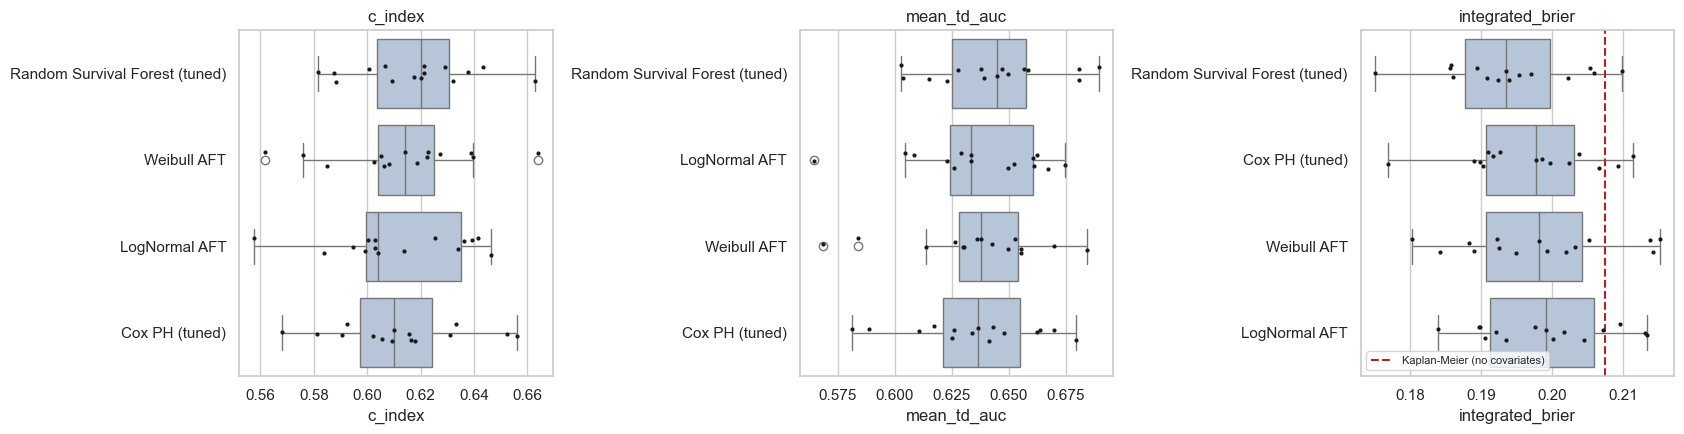

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, m in zip(axes, ["c_index", "mean_td_auc", "integrated_brier"]):
    order = scores.groupby("model")[m].mean().sort_values(ascending=(m == "integrated_brier")).index
    sns.boxplot(data=scores, y="model", x=m, order=order, ax=ax, color="lightsteelblue")
    sns.stripplot(data=scores, y="model", x=m, order=order, ax=ax, color="k", size=3)
    ax.set(ylabel="", title=m)
    if m == "integrated_brier":
        ax.axvline(scores["km_ibs"].mean(), ls="--", c="firebrick", label="Kaplan-Meier (no covariates)")
        ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(config.FIGURES_DIR / "06_cv_scores.png", dpi=120, bbox_inches="tight")

## 4 · Comparação estatística e seleção / Statistical comparison & selection

In [7]:
best = scores.groupby("model")["c_index"].mean().idxmax()
pd.DataFrame([
    evaluation.corrected_paired_ttest(scores, best, other, metric)
    for other in fitters if other != best
    for metric in ["c_index", "integrated_brier"]
])

,comparison,metric,mean_diff,ci95_low,ci95_high,share_folds_a_better,t,p_value
0,Random Survival Forest (tuned) − Cox PH (tuned),c_index,0.005,-0.018,0.029,0.600,0.481,0.638
1,Random Survival Forest (tuned) − Cox PH (tuned),integrated_brier,-0.003,-0.007,0.001,0.800,-1.502,0.155
2,Random Survival Forest (tuned) − Weibull AFT,c_index,0.004,-0.023,0.032,0.533,0.351,0.731
3,Random Survival Forest (tuned) − Weibull AFT,integrated_brier,-0.004,-0.012,0.003,0.800,-1.199,0.250
4,Random Survival Forest (tuned) − LogNormal AFT,c_index,0.005,-0.022,0.032,0.667,0.416,0.684
5,Random Survival Forest (tuned) − LogNormal AFT,integrated_brier,-0.005,-0.013,0.002,0.733,-1.468,0.164


**Regra de seleção (definida antes de ver o teste final):** escolher o modelo com menor
**Integrated Brier Score** médio na CV, que combina discriminação e calibração. Se ele **não** for
significativamente melhor que o Cox (t-test corrigido, α = 0,05), escolher o **Cox**, que é mais
interpretável para o RH.

In [8]:
choice = evaluation.select_model(scores, preferred="Cox PH (tuned)", metric="integrated_brier")
choice

{'selected': 'Cox PH (tuned)',
 'best_by_cv': 'Random Survival Forest (tuned)',
 'p_value': np.float64(0.15521635632838768),
 'reason': 'Random Survival Forest (tuned) not significantly better (p=0.16); prefer Cox PH (tuned)'}

## 5 · Calibração out-of-fold / Out-of-fold calibration

,12 months,24 months
,mean_abs_calibration_error,mean_abs_calibration_error
model,,
Cox PH (tuned),0.015,0.031
Random Survival Forest (tuned),0.015,0.026
Weibull AFT,0.029,0.054
LogNormal AFT,0.045,0.046


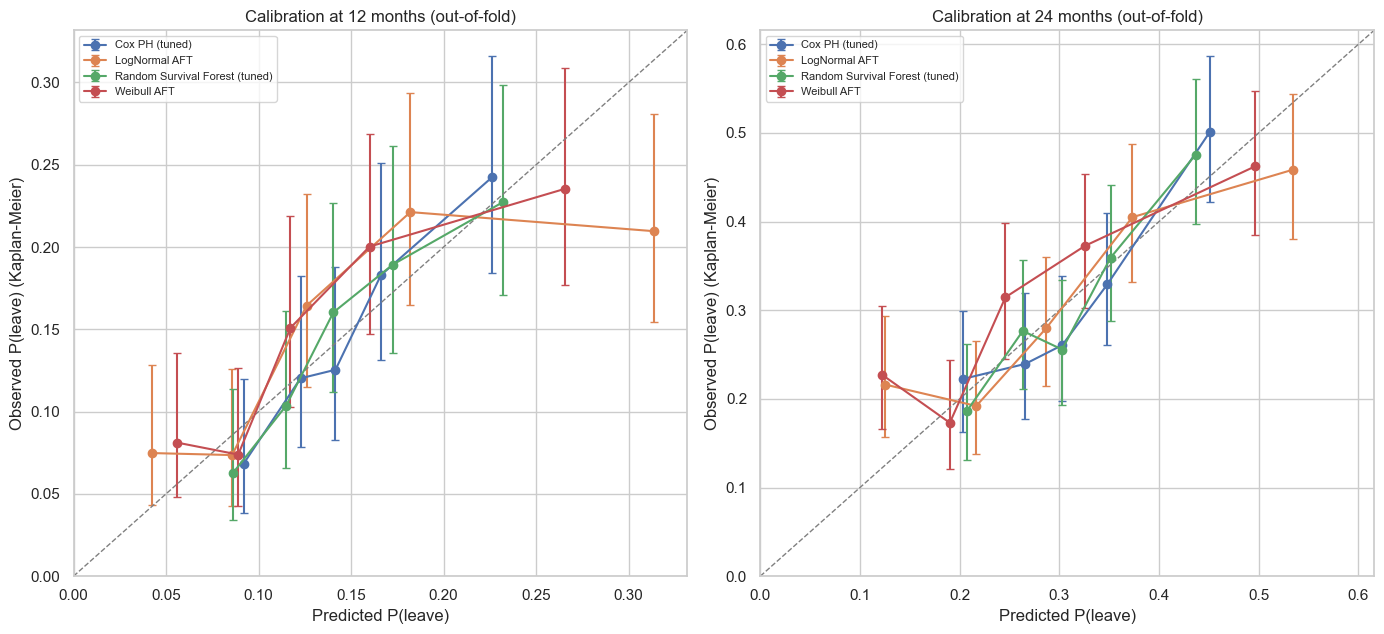

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6.5))
cal = {}
for ax, h in zip(axes, [12, 24]):
    cal[h] = evaluation.calibration_table(oof, dev, horizon=h, n_bins=5)
    evaluation.plot_calibration(cal[h], horizon=h, ax=ax)
fig.tight_layout()
fig.savefig(config.FIGURES_DIR / "06_calibration.png", dpi=120, bbox_inches="tight")
pd.concat({f"{h} months": evaluation.calibration_summary(t) for h, t in cal.items()}, axis=1)

Cada ponto é um quintil de risco previsto; sobre a diagonal = bem calibrado. Pontos **acima** →
o modelo **subestima** o risco de saída nesse grupo; **abaixo** → superestima.

## 6 · Teste final (avaliado uma única vez) / Final hold-out test (one shot)
Pré-processamento e modelos ajustados em **todo o desenvolvimento** e avaliados no teste final.
IC 95% por **bootstrap agrupado por perfil** (500 reamostragens). Os demais modelos aparecem só
como contexto: a escolha já foi feita na seção 4 e **não muda** com este resultado.

In [10]:
final, final_models = evaluation.holdout_evaluate(dev, holdout, fitters, n_boot=500)
final["selected"] = final["model"].eq(choice["selected"])
cv_means = scores.groupby("model")[["c_index", "integrated_brier"]].mean().add_prefix("cv_")
final = final.merge(cv_means, left_on="model", right_index=True, how="left")
final.to_csv(config.DATA_PROCESSED / "final_holdout.csv", index=False)
final

,model,c_index,c_index_low,c_index_high,integrated_brier,ibs_low,ibs_high,selected,cv_c_index,cv_integrated_brier
0,Cox PH (tuned),0.626,0.563,0.686,0.173,0.152,0.196,True,0.612,0.197
1,Weibull AFT,0.625,0.559,0.689,0.169,0.145,0.197,False,0.613,0.198
2,LogNormal AFT,0.620,0.556,0.683,0.172,0.148,0.196,False,0.612,0.199
3,Random Survival Forest (tuned),0.604,0.533,0.672,0.172,0.150,0.194,False,0.617,0.194
4,Kaplan-Meier (no covariates),0.500,0.500,0.500,0.186,0.163,0.208,False,NaN,NaN


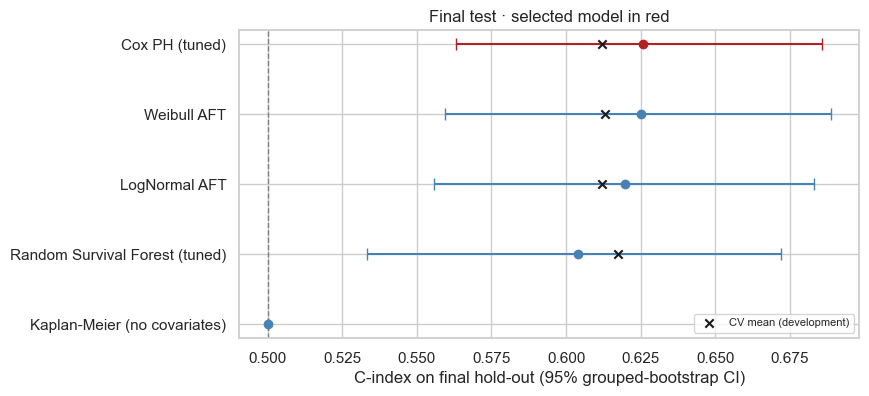

In [11]:
fig, ax = plt.subplots(figsize=(8, 4))
f = final.sort_values("c_index")
for _, r in f.iterrows():
    color = "firebrick" if r["selected"] else "steelblue"
    ax.errorbar(r["c_index"], r["model"], xerr=[[r["c_index"] - r["c_index_low"]], [r["c_index_high"] - r["c_index"]]],
                fmt="o", color=color, capsize=4)
ax.scatter(f["cv_c_index"], f["model"], marker="x", c="k", label="CV mean (development)", zorder=3)
ax.axvline(0.5, ls="--", c="grey", lw=1)
ax.set(xlabel="C-index on final hold-out (95% grouped-bootstrap CI)", title="Final test · selected model in red")
ax.legend(fontsize=8)
fig.savefig(config.FIGURES_DIR / "06_final_holdout.png", dpi=120, bbox_inches="tight")

**Leitura:** se o resultado no teste final cai dentro da faixa vista na CV (× no gráfico), a
estimativa do desenvolvimento era honesta. Uma queda grande indicaria otimismo na seleção, o que
este protocolo existe justamente para revelar.

### Conclusões / Takeaways
> _Preencha após rodar com os dados reais. / Fill in after running on the real data._